1. Libraries and settings
Import the tools needed for data processing, statistical checks and visualization.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from kagglehub import KaggleDatasetAdapter
from pathlib import Path

2. Locate project folders
Use paths relative to the repository so the notebook works on every teammate’s computer.

In [7]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("harshalhonde/property-rental-listings-dataset")

print("Path to dataset files:", path)

100%|██████████| 987k/987k [00:00<00:00, 2.24MB/s]

Extracting files...
Path to dataset files: C:\Users\nandi\.cache\kagglehub\datasets\harshalhonde\property-rental-listings-dataset\versions\2


In [8]:
print ("Files in dataset:")
for file in Path(path).glob("**/*"):
    print(file)

Files in dataset:
C:\Users\nandi\.cache\kagglehub\datasets\harshalhonde\property-rental-listings-dataset\versions\2\Mumbai_property_details.csv


3. Load the original dataset
Download the same Kaggle source used in the original notebook. This requires internet access on the first run.

In [7]:
import kagglehub
dataset_path = Path(kagglehub.dataset_download("harshalhonde/property-rental-listings-dataset"))
raw_path = dataset_path / "Mumbai_property_details.csv"
assert raw_path.exists(), f"Missing dataset: {raw_path}"
df_raw = pd.read_csv(raw_path)
print("Raw shape:", df_raw.shape)
display(df_raw.head())

Raw shape: (23405, 18)


,Title,Price,Area,BHK,Bathrooms,Furnished,Balconies,Floor,Ownership,Facing,Amenities,Transaction Type,Property Type,Location,Year of Construction,Is Luxury,Description,Property Image
0,1BHK Multistorey Apartment for Rent in Bandra ...,"70,000",750 12800,1,1,Furnished,NaN,7,NaN,South -West,Main Road,Rent,Apartment,Mumbai,2012.0,F,"1 BHK, Multistorey Apartment is available for ...",67249079_2_PropertyImage345-4855396928822.jpg
1,3BHK Multistorey Apartment for Rent in Lodha N...,1.4 Lac,1980 12800,3,4,Unfurnished,4,21,NaN,East,"Garden/Park, Pool, Main Road",Rent,Apartment,Mumbai,1994.0,F,"3 BHK, Multistorey Apartment is available for ...",66155783_5_hatsAppImage20230217at13.56.28.jpeg
2,3BHK Multistorey Apartment for Rent in Lodha P...,1.9 Lac,1592 12800,3,3,Unfurnished,1,20,NaN,North - East,Main Road,Rent,Apartment,Mumbai,NaN,F,"3 BHK, Multistorey Apartment is available for ...",66686709_1_HOTO20230407165614.jpg
3,3BHK Multistorey Apartment for Rent in Rustomj...,1.1 Lac,1305 12800,3,3,Unfurnished,3,11,Freehold,West,"Garden/Park, Main Road",Rent,Apartment,Mumbai,2010.0,F,"3 BHK, Multistorey Apartment is available for ...",67875387_1_PropertyImage559-8385323621333.jpg
4,3BHK Multistorey Apartment for Rent in DLH The...,1.4 Lac,1350 12800,3,3,Unfurnished,NaN,29,Freehold,East,"Pool, Garden/Park, Main Road",Rent,Apartment,Mumbai,2000.0,F,"3 BHK, Multistorey Apartment is available for ...",66670931_3_PropertyImage314-6685675359874.jpg


4. Inspect schema
Check the original column names and inferred data types before any transformations

In [3]:
project_root = Path.cwd().resolve()
if project_root.name == "notebooks":
    project_root = project_root.parent
clean_dir = project_root / "data" / "cleaned"
clean_dir.mkdir(parents=True, exist_ok=True)
print("Repository:", project_root)

Repository: D:\Work\IAAC\AI_Methods\DAY 1\Practice\Group3-day1assignment


In [9]:
print(df_raw.dtypes.to_string())
print("Columns:", df_raw.columns.tolist())

Title                       str
Price                       str
Area                        str
BHK                         str
Bathrooms                   str
Furnished                   str
Balconies                   str
Floor                       str
Ownership                   str
Facing                      str
Amenities                   str
Transaction Type            str
Property Type               str
Location                    str
Year of Construction    float64
Is Luxury                   str
Description                 str
Property Image              str
Columns: ['Title', 'Price', 'Area', 'BHK', 'Bathrooms', 'Furnished', 'Balconies', 'Floor', 'Ownership', 'Facing', 'Amenities', 'Transaction Type', 'Property Type', 'Location', 'Year of Construction', 'Is Luxury', 'Description', 'Property Image']


5. Audit missing values and exact duplicates
Establish baseline quality indicators. These values are used to compare results after cleaning.

In [11]:
raw_rows = len(df_raw)
raw_duplicates = int(df_raw.duplicated().sum())
missing_before = df_raw.isna().sum().sort_values(ascending=False)
print("Rows:", raw_rows, "Exact duplicates:", raw_duplicates)
display(missing_before.to_frame("Missing values"))

Rows: 23405 Exact duplicates: 3111


,Missing values
Ownership,20570
Balconies,13017
Year of Construction,8520
Amenities,5313
Facing,4281
Property Image,3798
Floor,1120
BHK,411
Bathrooms,204
Furnished,189


6. Initialize working copy
Preserve the original dataframe and normalize whitespace without changing missing values.

In [12]:
df_clean = df_raw.copy()
text_columns = df_clean.select_dtypes(include=["object", "string"]).columns
for col in text_columns:
    df_clean[col] = df_clean[col].astype("string").str.strip()
    df_clean[col] = df_clean[col].replace({"": pd.NA, "None": pd.NA, "nan": pd.NA})
print(df_clean.shape)

(23405, 18)


7. Convert rental prices
The original dataset mixes INR amounts, Lac (100,000 INR), Cr (10,000,000 INR), and nonnumeric text.

In [13]:
def convert_price(value):
    if pd.isna(value): return np.nan
    text = str(value).strip().replace(",", "")
    if text.lower() == "call for price": return np.nan
    import re
    match = re.fullmatch(r"([0-9]+(?:\.[0-9]+)?)\s*(lac|lakh|cr|crore)?", text, flags=re.I)
    if not match: return np.nan
    amount = float(match.group(1))
    suffix = (match.group(2) or "").lower()
    return amount * ({"lac":100_000, "lakh":100_000, "cr":10_000_000, "crore":10_000_000}.get(suffix, 1))
df_clean["Price"] = df_clean["Price"].map(convert_price)
display(df_clean["Price"].describe())

count    2.318600e+04
mean     1.229191e+05
std      6.789939e+05
min      1.800000e+03
25%      3.908300e+04
50%      6.500000e+04
75%      1.200000e+05
max      4.000000e+07
Name: Price, dtype: float64

8. Parse property area
The original Area strings often contain a trailing 12800 token. Follow the original notebook by extracting the first numeric token; the original file does not document its physical unit.

In [14]:
area_token = df_clean["Area"].str.extract(r"^\s*([0-9][0-9,]*(?:\.[0-9]+)?)")[0]
df_clean["Area"] = pd.to_numeric(area_token.str.replace(",", "", regex=False), errors="coerce")
display(df_clean["Area"].describe())

count        22332.0
mean     1214.907263
std       815.991839
min              2.0
25%            700.0
50%           1050.0
75%           1450.0
max          15000.0
Name: Area, dtype: Float64

9. Convert bedroom and bathroom counts
Treat > 10 as unknown instead of inventing a specific number.

In [15]:
for col in ["BHK", "Bathrooms", "Balconies"]:
    df_clean[col] = pd.to_numeric(df_clean[col].replace({"> 10": pd.NA}), errors="coerce")
print(df_clean[["BHK", "Bathrooms", "Balconies"]].dtypes)

BHK          Int64
Bathrooms    Int64
Balconies    Int64
dtype: object


10. Standardize floor levels
Encode ground level as zero and basement levels as negative numbers, matching the original notebook.

In [16]:
floor_map = {"Ground": 0, "Upper Basement": -1, "Lower Basement": -2}
df_clean["Floor"] = pd.to_numeric(df_clean["Floor"].replace(floor_map), errors="coerce")
print(df_clean["Floor"].value_counts(dropna=False).head(12))

Floor
5.0     2087
4.0     1871
3.0     1743
2.0     1572
7.0     1345
10.0    1326
6.0     1282
1.0     1256
NaN     1120
9.0     1008
8.0      935
12.0     886
Name: count, dtype: int64


11. Standardize categorical fields
Normalize whitespace and obvious formatting differences while retaining unknown categories as missing.

In [17]:
categorical = ["Furnished", "Ownership", "Facing", "Amenities", "Transaction Type", "Property Type", "Location", "Is Luxury"]
for col in categorical:
    df_clean[col] = df_clean[col].astype("string").str.replace(r"\s+", " ", regex=True).str.strip()
print(df_clean["Furnished"].value_counts(dropna=False))

Furnished
Semi-Furnished    9851
Unfurnished       7281
Furnished         6084
<NA>               189
Name: count, dtype: Int64


12. Apply documented missing-value rules
Retain missing numeric values rather than imputing unverified information. Use Unknown only for descriptive categories, as in the original.

In [18]:
for col in ["Ownership", "Facing", "Amenities", "Is Luxury"]:
    df_clean[col] = df_clean[col].fillna("Unknown")
# Do not automatically assume missing transaction types are Rent.
print(df_clean.isna().sum().sort_values(ascending=False).head(10))

Balconies               13018
Year of Construction     8520
Property Image           3798
Floor                    1120
Area                     1073
BHK                       414
Price                     219
Bathrooms                 206
Furnished                 189
Transaction Type            7
dtype: int64


13. Validate construction years
Flag implausible construction years rather than silently replacing them.

In [19]:
df_clean["Year of Construction"] = pd.to_numeric(df_clean["Year of Construction"], errors="coerce")
invalid_year = df_clean["Year of Construction"].notna() & ~df_clean["Year of Construction"].between(1800, 2026)
print("Construction years requiring review:", int(invalid_year.sum()))

Construction years requiring review: 0


14. Remove exact duplicates
Drop repeated records once, after standardized conversion. This can detect additional duplicates compared with the raw audit.

In [20]:
before_dedup = len(df_clean)
df_clean = df_clean.drop_duplicates().copy()
print("Duplicates removed:", before_dedup-len(df_clean))
print("Rows remaining:", len(df_clean))

Duplicates removed: 3111
Rows remaining: 20294


15. Mark invalid prices
Nonpositive rents are not valid for price analysis; flag them before making any exclusion decision.

In [22]:
df_clean["Invalid_Price"] = df_clean["Price"].notna() & (df_clean["Price"] <= 0)
print("Nonpositive prices:", int(df_clean["Invalid_Price"].sum()))

Nonpositive prices: 0


16. Review suspicious areas
The original notebook treated areas below 50 as unreliable. Flag them first; this threshold is a project heuristic, not a proven physical rule.

In [23]:
df_clean["Suspicious_Area"] = df_clean["Area"].notna() & (df_clean["Area"] < 50)
print("Areas below 50:", int(df_clean["Suspicious_Area"].sum()))

Areas below 50: 8


17. Calculate rent per area
Avoid division by zero and avoid treating areas below 50 as reliable denominators. Units depend on the source’s undocumented area convention.

In [24]:
valid_area = df_clean["Area"].where(df_clean["Area"] >= 50)
df_clean["Price_per_m2"] = df_clean["Price"] / valid_area
# Column name retained for compatibility with the original notebook; verify area units before interpreting as INR/m².
display(df_clean["Price_per_m2"].describe())

count          19566.0
mean        100.507708
std        1155.519985
min           3.333333
25%          50.361359
50%          67.451089
75%          94.444444
max      130434.782609
Name: Price_per_m2, dtype: Float64

18. Flag extreme rental prices by BHK
Reproduce the original idea: flag prices above Q3 + 3×IQR for 1–3 BHK properties; do not remove them automatically.

In [25]:
df_clean["Suspicious_Price"] = False
for bhk in [1, 2, 3]:
    subset = df_clean.loc[df_clean["BHK"] == bhk, "Price"].dropna()
    if len(subset) < 4: continue
    q1, q3 = subset.quantile([.25, .75]); upper = q3 + 3*(q3-q1)
    df_clean.loc[(df_clean["BHK"] == bhk) & (df_clean["Price"] > upper), "Suspicious_Price"] = True
print("Suspicious prices:", int(df_clean["Suspicious_Price"].sum()))

Suspicious prices: 228


19. Summarize cleaning decisions
Record retained rows, missing data, and quality flags for reproducibility.

In [26]:
audit = pd.DataFrame({"Metric": ["Raw rows", "Raw exact duplicates", "Cleaned rows", "Remaining exact duplicates", "Suspicious areas", "Suspicious prices", "Nonpositive prices"], "Value": [raw_rows, raw_duplicates, len(df_clean), int(df_clean.duplicated().sum()), int(df_clean["Suspicious_Area"].sum()), int(df_clean["Suspicious_Price"].sum()), int(df_clean["Invalid_Price"].sum())]})
display(audit)

,Metric,Value
0,Raw rows,23405
1,Raw exact duplicates,3111
2,Cleaned rows,20294
3,Remaining exact duplicates,0
4,Suspicious areas,8
5,Suspicious prices,228
6,Nonpositive prices,0


20. Export cleaned dataset
Keep the cleaned, unfiltered dataset separate from any stricter analytical subset.

In [27]:
clean_path = clean_dir / "mumbai_rentals_refactored.csv"
df_clean.to_csv(clean_path, index=False)
print("Saved:", clean_path, "Shape:", df_clean.shape)

Saved: D:\Work\IAAC\AI_Methods\DAY 1\Practice\Group3-day1assignment\data\cleaned\mumbai_rentals_refactored.csv Shape: (20294, 22)


21. Visualize price distribution
Use a logarithmic axis to examine highly skewed rental prices without discarding extreme observations.

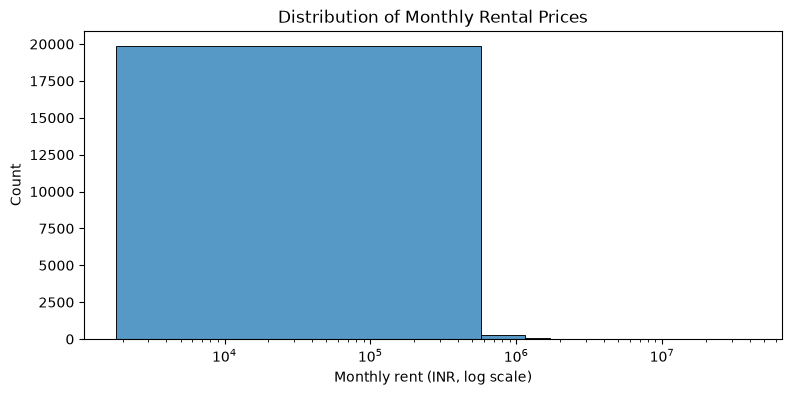

In [28]:
plot_data = df_clean.loc[df_clean["Price"] > 0, "Price"].dropna()
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(plot_data, bins=70, ax=ax)
ax.set_xscale("log"); ax.set_title("Distribution of Monthly Rental Prices")
ax.set_xlabel("Monthly rent (INR, log scale)"); plt.show()

22. Compare rent by bedroom count
Use both medians and means because high-end listings can inflate averages.

,count,median,mean
BHK,,,
1,4663,35000.0,65396.955179
2,8233,65000.0,82292.282522
3,5423,130000.0,151573.662917
4,1426,280000.0,363508.485273
5,220,465000.0,557093.181818
6,36,430000.0,699166.666667
7,7,900000.0,967142.857143


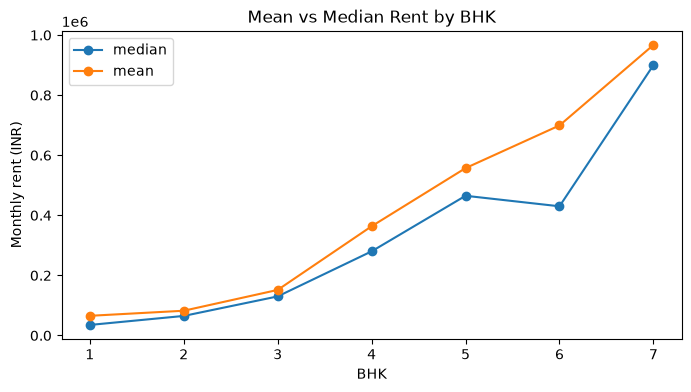

In [29]:
bhk_summary = df_clean.groupby("BHK")["Price"].agg(["count", "median", "mean"])
display(bhk_summary)
bhk_summary.loc[bhk_summary.index.isin(range(1,8)), ["median", "mean"]].plot(marker="o", figsize=(8,4), title="Mean vs Median Rent by BHK")
plt.ylabel("Monthly rent (INR)"); plt.show()

23. Detect IQR outliers by BHK
Calculate a statistical outlier flag separately within each bedroom group. IQR outliers are not automatically errors.

In [30]:
df_clean["IQR_Price_Outlier"] = False
for bhk, group in df_clean.groupby("BHK"):
    prices = group["Price"].dropna()
    if len(prices) < 4: continue
    q1, q3 = prices.quantile([.25,.75]); iqr=q3-q1
    df_clean.loc[group.index, "IQR_Price_Outlier"] = group["Price"].gt(q3+1.5*iqr) | group["Price"].lt(q1-1.5*iqr)
print(df_clean["IQR_Price_Outlier"].value_counts())

IQR_Price_Outlier
False    19173
True      1121
Name: count, dtype: int64


24. Inspect rent-per-area extremes
Flag extreme unit-price observations using robust quantiles without removing them.

In [32]:
unit_price = df_clean["Price_per_m2"].replace([np.inf,-np.inf],np.nan)
if unit_price.notna().sum() > 0:
    lo, hi = unit_price.quantile([.01,.99])
    df_clean["Extreme_Unit_Price"] = unit_price.notna() & ~unit_price.between(lo,hi)
else:
    df_clean["Extreme_Unit_Price"] = False

print("Unit-price extremes:", int(df_clean["Extreme_Unit_Price"].sum()))

Unit-price extremes: 392


25. Check inconsistent property attributes
Flag records with negative counts or a number of bathrooms that is unusually large relative to BHK.

In [33]:
df_clean["Inconsistent_Attributes"] = (df_clean[["BHK","Bathrooms","Balconies"]].lt(0).any(axis=1) | (df_clean["Bathrooms"] > df_clean["BHK"] + 4))
print("Potential attribute inconsistencies:", int(df_clean["Inconsistent_Attributes"].sum()))

Potential attribute inconsistencies: 0


26. Find potential near-duplicate listings
Use a subset of listing attributes to identify candidates for manual review. Similar listings may represent different units.

In [34]:
keys = ["Title", "Price", "Area", "BHK", "Property Type"]
df_clean["Potential_Duplicate"] = df_clean.duplicated(subset=keys, keep=False)
print("Potential duplicate candidates:", int(df_clean["Potential_Duplicate"].sum()))
display(df_clean.loc[df_clean["Potential_Duplicate"], keys].head(10))

Potential duplicate candidates: 3385


,Title,Price,Area,BHK,Property Type
0,1BHK Multistorey Apartment for Rent in Bandra ...,70000.0,750,1,Apartment
3,3BHK Multistorey Apartment for Rent in Rustomj...,110000.0,1305,3,Apartment
4,3BHK Multistorey Apartment for Rent in DLH The...,140000.0,1350,3,Apartment
14,2BHK Multistorey Apartment for Rent in Lodha P...,130000.0,1312,2,Apartment
17,4BHK Multistorey Apartment for Rent in Windsor...,450000.0,4300,4,Apartment
31,4BHK Multistorey Apartment for Rent in Celesti...,160000.0,2100,4,Apartment
37,3BHK Multistorey Apartment for Rent in Oberoi ...,170000.0,1820,3,Apartment
39,2BHK Multistorey Apartment for Rent in Ruparel...,90000.0,1100,2,Apartment
49,3BHK Multistorey Apartment for Rent in Celesti...,150000.0,2303,3,Apartment
50,3BHK Multistorey Apartment for Rent in Lokhand...,200000.0,2550,3,Apartment


27. Analyze missingness by property type
Determine whether missing data varies across property categories, rather than applying a blanket imputation rule.

In [35]:
missing_by_type = df_clean.groupby("Property Type", dropna=False)[["Balconies", "Year of Construction", "Floor"]].agg(lambda s: round(s.isna().mean()*100,1))
display(missing_by_type.head(15))

,Balconies,Year of Construction,Floor
Property Type,,,
Apartment,53.7,27.5,3.5
Builder Floor Apartment,86.0,90.9,3.3
Penthouse,16.7,37.5,0.0
Residential House,68.4,85.4,22.3
Service Apartment,100.0,100.0,0.0
Studio Apartment,83.6,54.8,0.6
Villa,30.1,56.2,100.0


28. Define conservative exclusion rules
Exclude only records with missing or nonpositive rent, missing or very small area, or negative bedroom/bathroom counts. Other anomalies remain flagged.

In [36]:
df_clean["Exclude_From_Price_Analysis"] = (df_clean["Price"].isna() | (df_clean["Price"] <= 0) | df_clean["Area"].isna() | (df_clean["Area"] < 50) | df_clean["BHK"].lt(0) | df_clean["Bathrooms"].lt(0))
print("Rows excluded from price analysis:", int(df_clean["Exclude_From_Price_Analysis"].sum()))

Rows excluded from price analysis: 728


29. Create filtered analytical subset
Preserve all other records, including plausible luxury listings and statistical outliers.

In [37]:
df_filtered = df_clean.loc[~df_clean["Exclude_From_Price_Analysis"]].copy()
print("Refactored rows:", len(df_clean), "Filtered rows:", len(df_filtered))
print("Excluded:", len(df_clean)-len(df_filtered))

Refactored rows: 20294 Filtered rows: 19372
Excluded: 922


30. Compare and export datasets
Save the filtered subset and an exclusion audit. Do not claim the row count is predetermined; it depends on actual data.

In [38]:
filtered_path = clean_dir / "mumbai_rentals_filtered.csv"
audit_path = clean_dir / "mumbai_rentals_cleaning_audit.csv"
df_filtered.to_csv(filtered_path, index=False)
df_clean.loc[df_clean["Exclude_From_Price_Analysis"]].to_csv(audit_path, index=False)
comparison = pd.DataFrame({"Dataset": ["Original raw", "Refactored cleaned", "Filtered analytical"], "Rows": [len(df_raw), len(df_clean), len(df_filtered)]})
display(comparison)
print("Saved:", filtered_path, "and", audit_path)

,Dataset,Rows
0,Original raw,23405
1,Refactored cleaned,20294
2,Filtered analytical,19372


Saved: D:\Work\IAAC\AI_Methods\DAY 1\Practice\Group3-day1assignment\data\cleaned\mumbai_rentals_filtered.csv and D:\Work\IAAC\AI_Methods\DAY 1\Practice\Group3-day1assignment\data\cleaned\mumbai_rentals_cleaning_audit.csv
